# Relational Database Design for ML Systems

## Why Databases Are the Memory of Your ML System

A trained model lives in memory. Everything else lives in a database:
- Which experiments ran? What hyperparameters?
- Which dataset version produced which model?
- What features were used for prediction #47,291?
- Which model is currently in production and who deployed it?

**Without a well-designed database, your ML system has no memory, no reproducibility, and no auditability.**

Relational databases (PostgreSQL, MySQL, SQLite) are still the backbone of ML metadata, experiment tracking, and prediction logging — even in cloud-native systems.

## Normalization — Designing Tables the Right Way

Normalization removes redundancy and prevents update anomalies.

### The Wrong Way — Denormalized
```
experiments table:
| exp_id | exp_name      | accuracy | precision | recall | f1   | run_date   |
|--------|---------------|----------|-----------|--------|------|------------|
| 1      | fraud-v1      | 0.91     | 0.88      | 0.93   | 0.90 | 2024-01-01 |
| 2      | fraud-v2      | 0.93     | 0.91      | 0.94   | 0.92 | 2024-01-05 |
```
**Problem:** Adding a new metric (e.g., AUC) requires an ALTER TABLE. Can't store per-epoch metrics.

### The Right Way — Normalized (3NF)
```
experiments: (exp_id, name, created_at)
runs:        (run_id, exp_id, status, started_at)
metrics:     (metric_id, run_id, name, value, step)
```
**✓ 1NF:** Each cell has one atomic value (not a list)  
**✓ 2NF:** No partial dependencies (every non-key column depends on the full primary key)  
**✓ 3NF:** No transitive dependencies (metric.name doesn't depend on experiment.name)

In [1]:
import sqlite3
import pandas as pd
from datetime import datetime, timedelta
import random

conn = sqlite3.connect(":memory:")
cur  = conn.cursor()

cur.executescript("""
PRAGMA foreign_keys = ON;

CREATE TABLE experiments (
    id         INTEGER PRIMARY KEY AUTOINCREMENT,
    name       TEXT    NOT NULL UNIQUE,
    owner      TEXT    NOT NULL,
    created_at TEXT    DEFAULT (datetime('now'))
);

CREATE TABLE runs (
    id            INTEGER PRIMARY KEY AUTOINCREMENT,
    experiment_id INTEGER NOT NULL REFERENCES experiments(id),
    status        TEXT    NOT NULL DEFAULT 'running',
    lr            REAL,
    n_estimators  INTEGER,
    dataset_hash  TEXT,
    started_at    TEXT    DEFAULT (datetime('now')),
    ended_at      TEXT
);

CREATE TABLE metrics (
    id         INTEGER PRIMARY KEY AUTOINCREMENT,
    run_id     INTEGER NOT NULL REFERENCES runs(id),
    name       TEXT    NOT NULL,
    value      REAL    NOT NULL,
    step       INTEGER DEFAULT 0,
    logged_at  TEXT    DEFAULT (datetime('now'))
);

CREATE TABLE artifacts (
    id             INTEGER PRIMARY KEY AUTOINCREMENT,
    run_id         INTEGER NOT NULL REFERENCES runs(id),
    artifact_type  TEXT    NOT NULL,
    path           TEXT    NOT NULL,
    size_bytes     INTEGER DEFAULT 0
);

-- Indexes for common query patterns
CREATE INDEX idx_runs_experiment ON runs(experiment_id);
CREATE INDEX idx_metrics_run     ON metrics(run_id);
CREATE INDEX idx_metrics_name    ON metrics(name);
""")

# Insert sample data
random.seed(42)
cur.execute("INSERT INTO experiments(name,owner) VALUES('fraud-detection','alice')")
cur.execute("INSERT INTO experiments(name,owner) VALUES('churn-prediction','bob')")

for exp_id in [1, 2]:
    for run_num in range(5):
        cur.execute("""INSERT INTO runs(experiment_id,status,lr,n_estimators,dataset_hash,ended_at)
                       VALUES(?,?,?,?,?,datetime('now'))""",
                    (exp_id,'completed', round(random.uniform(0.001,0.01),4),
                     random.choice([50,100,200]),f'hash_{exp_id}_{run_num}'))
        run_id = cur.lastrowid
        for step in range(10):
            base = 0.75 + run_num*0.02 + step*0.01
            cur.execute("INSERT INTO metrics(run_id,name,value,step) VALUES(?,?,?,?)",
                        (run_id,'accuracy', min(base+random.uniform(-0.005,0.005),0.99), step))
            cur.execute("INSERT INTO metrics(run_id,name,value,step) VALUES(?,?,?,?)",
                        (run_id,'loss', max(0.5-step*0.04+random.uniform(-0.01,0.01),0.05), step))
        cur.execute("INSERT INTO artifacts(run_id,artifact_type,path,size_bytes) VALUES(?,?,?,?)",
                    (run_id,'model',f's3://models/run_{run_id}.pkl', random.randint(1_000_000,50_000_000)))

conn.commit()
print("✓ Schema created and sample data inserted")
print(f"  Experiments: {cur.execute('SELECT COUNT(*) FROM experiments').fetchone()[0]}")
print(f"  Runs:        {cur.execute('SELECT COUNT(*) FROM runs').fetchone()[0]}")
print(f"  Metrics:     {cur.execute('SELECT COUNT(*) FROM metrics').fetchone()[0]}")

✓ Schema created and sample data inserted
  Experiments: 2
  Runs:        10
  Metrics:     200


In [2]:
# Common ML metadata queries
print("=" * 55)
print("1. Best run per experiment (by final accuracy)")
print("=" * 55)
q1 = pd.read_sql_query("""
    SELECT e.name AS experiment, r.id AS run_id,
           r.lr, r.n_estimators,
           ROUND(MAX(m.value),4) AS best_accuracy
    FROM   experiments e
    JOIN   runs r ON r.experiment_id = e.id
    JOIN   metrics m ON m.run_id = r.id AND m.name = 'accuracy'
    GROUP  BY e.name, r.id
    ORDER  BY best_accuracy DESC
    LIMIT  5
""", conn)
print(q1.to_string(index=False))

print("\n" + "=" * 55)
print("2. Learning curve — avg loss per step (experiment 1)")
print("=" * 55)
q2 = pd.read_sql_query("""
    SELECT m.step,
           ROUND(AVG(m.value),4) AS avg_loss,
           ROUND(MIN(m.value),4) AS min_loss,
           ROUND(MAX(m.value),4) AS max_loss
    FROM   metrics m
    JOIN   runs r ON r.id = m.run_id
    WHERE  r.experiment_id = 1 AND m.name = 'loss'
    GROUP  BY m.step
    ORDER  BY m.step
""", conn)
print(q2.to_string(index=False))

1. Best run per experiment (by final accuracy)
      experiment  run_id     lr  n_estimators  best_accuracy
 fraud-detection       5 0.0087            50         0.9245
churn-prediction      10 0.0097            50         0.9208
churn-prediction       9 0.0048           100         0.9015
 fraud-detection       4 0.0082           100         0.9001
 fraud-detection       3 0.0087            50         0.8827

2. Learning curve — avg loss per step (experiment 1)
 step  avg_loss  min_loss  max_loss
    0    0.4999    0.4942    0.5058
    1    0.4563    0.4513    0.4675
    2    0.4228    0.4169    0.4299
    3    0.3806    0.3706    0.3894
    4    0.3351    0.3302    0.3427
    5    0.2985    0.2916    0.3036
    6    0.2598    0.2553    0.2640
    7    0.2180    0.2122    0.2238
    8    0.1809    0.1714    0.1900
    9    0.1378    0.1311    0.1475


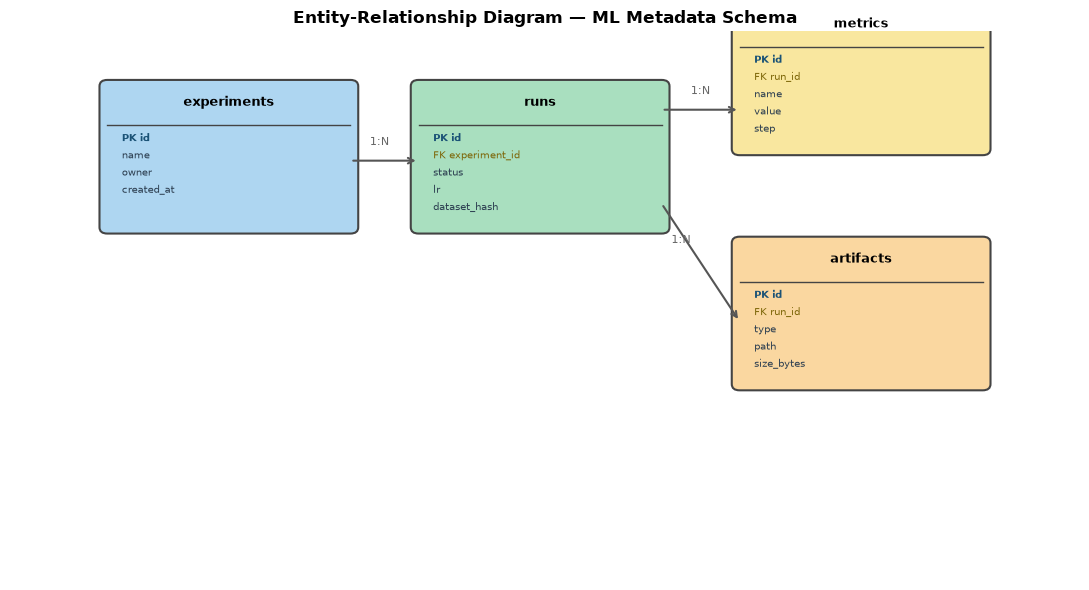

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(11, 6))
ax.set_xlim(0, 11); ax.set_ylim(0, 7); ax.axis('off')
ax.set_title('Entity-Relationship Diagram — ML Metadata Schema', fontsize=12, fontweight='bold')

tables = {
    'experiments': (1.0, 4.5, ['PK id','name','owner','created_at'], '#AED6F1'),
    'runs':        (4.2, 4.5, ['PK id','FK experiment_id','status','lr','dataset_hash'], '#A9DFBF'),
    'metrics':     (7.5, 5.5, ['PK id','FK run_id','name','value','step'], '#F9E79F'),
    'artifacts':   (7.5, 2.5, ['PK id','FK run_id','type','path','size_bytes'], '#FAD7A0'),
}

for tname, (x, y, cols, color) in tables.items():
    ax.add_patch(mpatches.FancyBboxPatch((x,y), 2.5, 1.8,
        boxstyle='round,pad=0.08', facecolor=color, edgecolor='#444', lw=1.5))
    ax.text(x+1.25, y+1.55, tname, ha='center', fontsize=9, fontweight='bold')
    ax.plot([x, x+2.5], [y+1.3, y+1.3], '-', color='#444', lw=1)
    for i, col in enumerate(cols):
        style = 'bold' if col.startswith('PK') else 'normal'
        color_t = '#1a5276' if col.startswith('PK') else ('#7d6608' if col.startswith('FK') else '#2c3e50')
        ax.text(x+0.15, y+1.1-i*0.22, col, fontsize=7.5, fontweight=style, color=color_t)

# Relationship lines
ax.annotate('', xy=(4.2,5.35), xytext=(3.5,5.35),
    arrowprops=dict(arrowstyle='->', color='#555', lw=1.5))
ax.annotate('', xy=(7.5,6.0), xytext=(6.7,6.0),
    arrowprops=dict(arrowstyle='->', color='#555', lw=1.5))
ax.annotate('', xy=(7.5,3.3), xytext=(6.7,4.8),
    arrowprops=dict(arrowstyle='->', color='#555', lw=1.5))

ax.text(3.7,5.55,'1:N',fontsize=8,color='#666')
ax.text(7.0,6.2,'1:N',fontsize=8,color='#666')
ax.text(6.8,4.3,'1:N',fontsize=8,color='#666')

plt.tight_layout(); plt.show()

## Indexing — The Most Important Optimization

An index is a separate data structure (usually a **B-Tree**) that lets the database find rows without scanning every row.

**B-Tree mechanics:** Sorted tree, O(log n) lookup. For 1M rows, a full scan = 1,000,000 comparisons. A B-Tree index = ~20 comparisons.

### When to Add an Index
✅ Column appears frequently in `WHERE`, `JOIN ON`, `ORDER BY`  
✅ High cardinality (many distinct values) — e.g., `run_id`, `user_id`  
✅ Foreign key columns  

### When NOT to Add an Index
❌ Write-heavy tables (every INSERT/UPDATE must also update all indexes)  
❌ Low cardinality — e.g., `status IN ('running','completed','failed')` — index not selective enough  
❌ Small tables (< 10k rows) — full scan is faster than index overhead  

### Composite Indexes
```sql
CREATE INDEX idx_metrics_run_name ON metrics(run_id, name);
-- Optimizes: WHERE run_id = 5 AND name = 'accuracy'
-- Column order matters: leftmost prefix rule
```

In [4]:
import timeit

# Show query plan and measure speedup with/without index
conn_test = sqlite3.connect(":memory:")
cur_test = conn_test.cursor()

# Create large table WITHOUT index first
cur_test.execute("CREATE TABLE big_metrics(run_id INT, name TEXT, value REAL, step INT)")
cur_test.executemany("INSERT INTO big_metrics VALUES(?,?,?,?)",
    [(random.randint(1,1000),'accuracy',random.random(),i) for i in range(200_000)])
conn_test.commit()

query = "SELECT AVG(value) FROM big_metrics WHERE run_id = 42 AND name = 'accuracy'"

print("EXPLAIN QUERY PLAN (no index):")
for row in cur_test.execute(f"EXPLAIN QUERY PLAN {query}"):
    print(" ", row)

t_no_index = timeit.timeit(lambda: cur_test.execute(query).fetchone(), number=50)

# Add composite index
cur_test.execute("CREATE INDEX idx_run_name ON big_metrics(run_id, name)")

print("\nEXPLAIN QUERY PLAN (with index):")
for row in cur_test.execute(f"EXPLAIN QUERY PLAN {query}"):
    print(" ", row)

t_with_index = timeit.timeit(lambda: cur_test.execute(query).fetchone(), number=50)

print(f"\nTime without index: {t_no_index*1000/50:.2f}ms per query")
print(f"Time with index:    {t_with_index*1000/50:.2f}ms per query")
print(f"Speedup:            {t_no_index/t_with_index:.1f}x")

EXPLAIN QUERY PLAN (no index):
  (3, 0, 0, 'SCAN big_metrics')



EXPLAIN QUERY PLAN (with index):
  (4, 0, 0, 'SEARCH big_metrics USING INDEX idx_run_name (run_id=? AND name=?)')

Time without index: 9.78ms per query
Time with index:    0.10ms per query
Speedup:            99.0x


## Query Optimization Patterns

| Anti-Pattern | Problem | Fix |
|-------------|---------|-----|
| `SELECT *` | Fetches unused columns, wastes I/O | `SELECT id, name, value` |
| N+1 queries | 1 query to get N runs, then N queries for metrics | `JOIN` in one query |
| No `LIMIT` | Full scan on large table | `LIMIT 100` for pagination |
| Function on indexed col | `WHERE YEAR(created_at) = 2024` bypasses index | `WHERE created_at >= '2024-01-01'` |
| Implicit type cast | `WHERE id = '5'` (int vs string) | Match types explicitly |

### ACID Properties — Why They Matter for ML
- **Atomicity**: A training run either fully writes (all metrics) or nothing. No half-written runs.
- **Consistency**: Foreign key constraints prevent orphaned metrics (metrics without a valid run_id).
- **Isolation**: Two parallel training jobs writing metrics don't corrupt each other's data.
- **Durability**: Once a run is committed, a server crash doesn't lose it.

### Additional Learning Resources
- *Database Internals* — Alex Petrov (O'Reilly 2019)
- *Use The Index, Luke* — https://use-the-index-luke.com (free, excellent)
- PostgreSQL EXPLAIN docs: https://www.postgresql.org/docs/current/using-explain.html
- MLflow schema reference: https://mlflow.org/docs/latest/tracking.html